## Veri

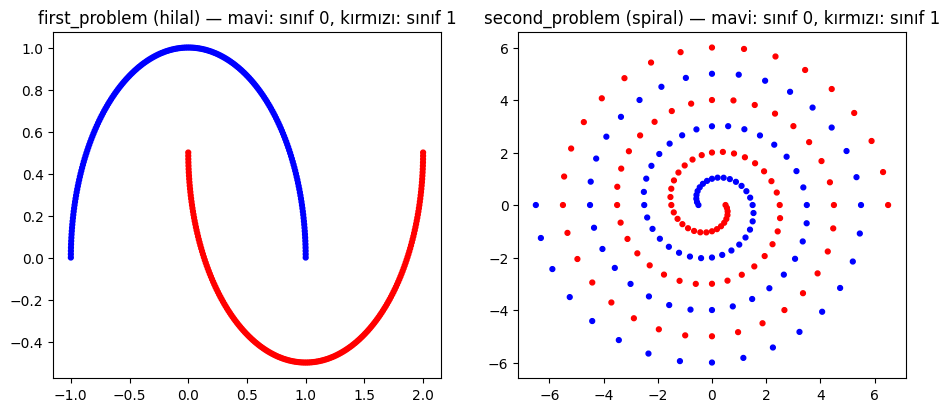

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df1 = pd.read_csv("first_problem.csv")
X1 = df1[["x1", "x2"]].to_numpy()
y1 = df1["label"].to_numpy()

df2 = pd.read_csv("second_problem.csv")
X2 = df2[["x1", "x2"]].to_numpy()
y2 = df2["label"].to_numpy()

datasets = {
    "first_problem (hilal)":   (X1, y1),
    "second_problem (spiral)": (X2, y2),
}

plt.figure(figsize=(11, 4.5))

plt.subplot(1, 2, 1)
plt.scatter(X1[:, 0], X1[:, 1], c=y1, cmap="bwr", s=12)
plt.title("first_problem (hilal) — mavi: sınıf 0, kırmızı: sınıf 1")

plt.subplot(1, 2, 2)
plt.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="bwr", s=12)
plt.title("second_problem (spiral) — mavi: sınıf 0, kırmızı: sınıf 1")

plt.show()

## Madde 1

In [2]:
X_or = np.array([[1, 0, 0],
                 [1, 0, 1],
                 [1, 1, 0],
                 [1, 1, 1]])
y_or = np.array([0, 1, 1, 1])

w = np.zeros(3)
eta = 0.5

for epoch in range(4):
    for i in range(4):
        x = X_or[i]
        y = y_or[i]

        s = w @ x
        if s > 0:
            y_hat = 1
        else:
            y_hat = 0

        w = w + eta * (y - y_hat) * x

    print("tur", epoch + 1, "sonunda w =", w)

tur 1 sonunda w = [0.5 0.  0.5]
tur 2 sonunda w = [0.5 0.5 0.5]
tur 3 sonunda w = [0.  0.5 0.5]
tur 4 sonunda w = [0.  0.5 0.5]


In [3]:
w = np.zeros(3)
eta = 0.5

for epoch in range(5):
    for i in range(4):
        x = X_or[i]
        y = y_or[i]
        w = w + eta * x * y

    print("tur", epoch + 1, "sonunda w =", w)

tur 1 sonunda w = [1.5 1.  1. ]
tur 2 sonunda w = [3. 2. 2.]
tur 3 sonunda w = [4.5 3.  3. ]
tur 4 sonunda w = [6. 4. 4.]
tur 5 sonunda w = [7.5 5.  5. ]


## Madde 3

In [4]:
def step(s):
    return np.where(s > 0, 1.0, 0.0)


def init_weights(layers, seed):
    rng = np.random.default_rng(seed)
    weights = []
    for k in range(len(layers) - 1):
        n_in = layers[k]
        n_out = layers[k + 1]
        W = rng.uniform(-1, 1, size=(n_out, n_in + 1))
        weights.append(W)
    return weights


def forward(weights, X):
    activations = [X]
    a = X
    for W in weights:
        ones = np.ones((len(a), 1))
        a_with_bias = np.hstack([ones, a])
        s = a_with_bias @ W.T
        a = step(s)
        activations.append(a)
    return activations


def predict(weights, X):
    activations = forward(weights, X)
    output = activations[-1]
    return output[:, 0]


def accuracy(weights, X, y):
    y_hat = predict(weights, X)
    return np.mean(y_hat == y)

In [5]:
def train(X, y, layers, eta, epochs=50, seed=0, update_hidden=True):
    weights = init_weights(layers, seed)
    rng = np.random.default_rng(seed + 1000)
    last = len(weights) - 1

    history = []
    best_acc = 0
    best_weights = None

    for epoch in range(epochs):
        order = rng.permutation(len(X))

        for i in order:
            activations = forward(weights, X[i:i + 1])
            y_hat = activations[-1][0, 0]
            error = y[i] - y_hat

            if error != 0:
                for k in range(len(weights)):
                    if k == last or update_hidden:
                        layer_input = np.append(1, activations[k][0])
                        weights[k] = weights[k] + eta * error * layer_input

        acc = accuracy(weights, X, y)
        history.append(acc)

        if acc > best_acc:
            best_acc = acc
            best_weights = []
            for W in weights:
                best_weights.append(W.copy())

    return best_acc, best_weights, weights, history

In [6]:
def plot_boundary(weights, X, y, title):
    x1 = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200)
    x2 = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 200)
    g1, g2 = np.meshgrid(x1, x2)
    grid = np.column_stack([g1.ravel(), g2.ravel()])

    z = predict(weights, grid)
    z = z.reshape(g1.shape)

    plt.contourf(g1, g2, z, levels=[-0.5, 0.5, 1.5], colors=["blue", "red"], alpha=0.2)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", s=8)
    plt.title(title)

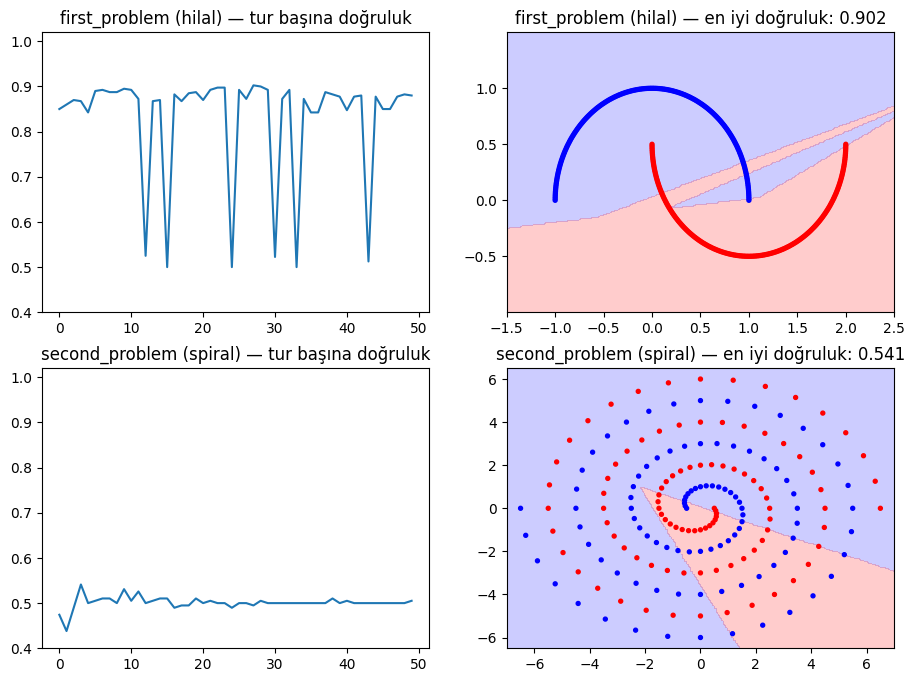

In [7]:
plt.figure(figsize=(11, 8))
k = 1

for name in datasets:
    X, y = datasets[name]
    best_acc, best_weights, final_weights, history = train(X, y, [2, 4, 1], 0.01)

    plt.subplot(2, 2, k)
    plt.plot(history)
    plt.ylim(0.4, 1.02)
    plt.title(name + " — tur başına doğruluk")

    plt.subplot(2, 2, k + 1)
    plot_boundary(best_weights, X, y, name + " — en iyi doğruluk: " + str(round(best_acc, 3)))

    k = k + 2

plt.show()

## Madde 4 ve 5

In [8]:
ARCHS = {
    "2-1":     [2, 1],
    "2-4-1":   [2, 4, 1],
    "2-16-1":  [2, 16, 1],
    "2-64-1":  [2, 64, 1],
    "2-8-8-1": [2, 8, 8, 1],
}
ETAS = [0.001, 0.01, 0.1, 1.0]
SEEDS = [0, 1, 2, 3, 4]

rows = []
best_models = {}

for data_name in datasets:
    X, y = datasets[data_name]

    for arch_name in ARCHS:
        layers = ARCHS[arch_name]

        for eta in ETAS:
            for seed in SEEDS:
                best_acc, best_weights, final_weights, history = train(X, y, layers, eta, seed=seed)
                rows.append([data_name, arch_name, eta, seed, best_acc])

                key = data_name + " " + arch_name
                if key not in best_models or best_acc > best_models[key][0]:
                    best_models[key] = [best_acc, best_weights, eta]

results = pd.DataFrame(rows, columns=["veri", "mimari", "eta", "seed", "doğruluk"])
print("toplam eğitim sayısı:", len(results))

toplam eğitim sayısı: 200


In [9]:
for data_name in datasets:
    part = results[results["veri"] == data_name]

    mean_table = part.pivot_table(index="mimari", columns="eta", values="doğruluk", aggfunc="mean")
    max_table = part.pivot_table(index="mimari", columns="eta", values="doğruluk", aggfunc="max")

    print(data_name, "— ortalama doğruluk")
    display(mean_table.reindex(list(ARCHS)).round(3))

    print(data_name, "— en iyi doğruluk")
    display(max_table.reindex(list(ARCHS)).round(3))

first_problem (hilal) — ortalama doğruluk


eta,0.001,0.010,0.100,1.000
mimari,,,,
2-1,0.883,0.884,0.888,0.886
2-4-1,0.870,0.899,0.895,0.862
2-16-1,0.962,0.976,0.912,0.863
2-64-1,0.964,0.996,0.912,0.864
2-8-8-1,0.877,0.894,0.859,0.649


first_problem (hilal) — en iyi doğruluk


eta,0.001,0.010,0.100,1.000
mimari,,,,
2-1,0.890,0.892,0.892,0.888
2-4-1,0.938,0.918,0.920,0.870
2-16-1,0.988,1.000,0.925,0.872
2-64-1,0.995,1.000,0.945,0.875
2-8-8-1,0.952,0.955,0.880,0.882


second_problem (spiral) — ortalama doğruluk


eta,0.001,0.010,0.100,1.000
mimari,,,,
2-1,0.545,0.548,0.545,0.543
2-4-1,0.539,0.531,0.505,0.505
2-16-1,0.544,0.544,0.512,0.505
2-64-1,0.562,0.556,0.512,0.505
2-8-8-1,0.526,0.529,0.506,0.515


second_problem (spiral) — en iyi doğruluk


eta,0.001,0.010,0.100,1.000
mimari,,,,
2-1,0.557,0.567,0.557,0.562
2-4-1,0.562,0.557,0.505,0.505
2-16-1,0.562,0.557,0.521,0.505
2-64-1,0.593,0.588,0.515,0.505
2-8-8-1,0.546,0.546,0.510,0.526


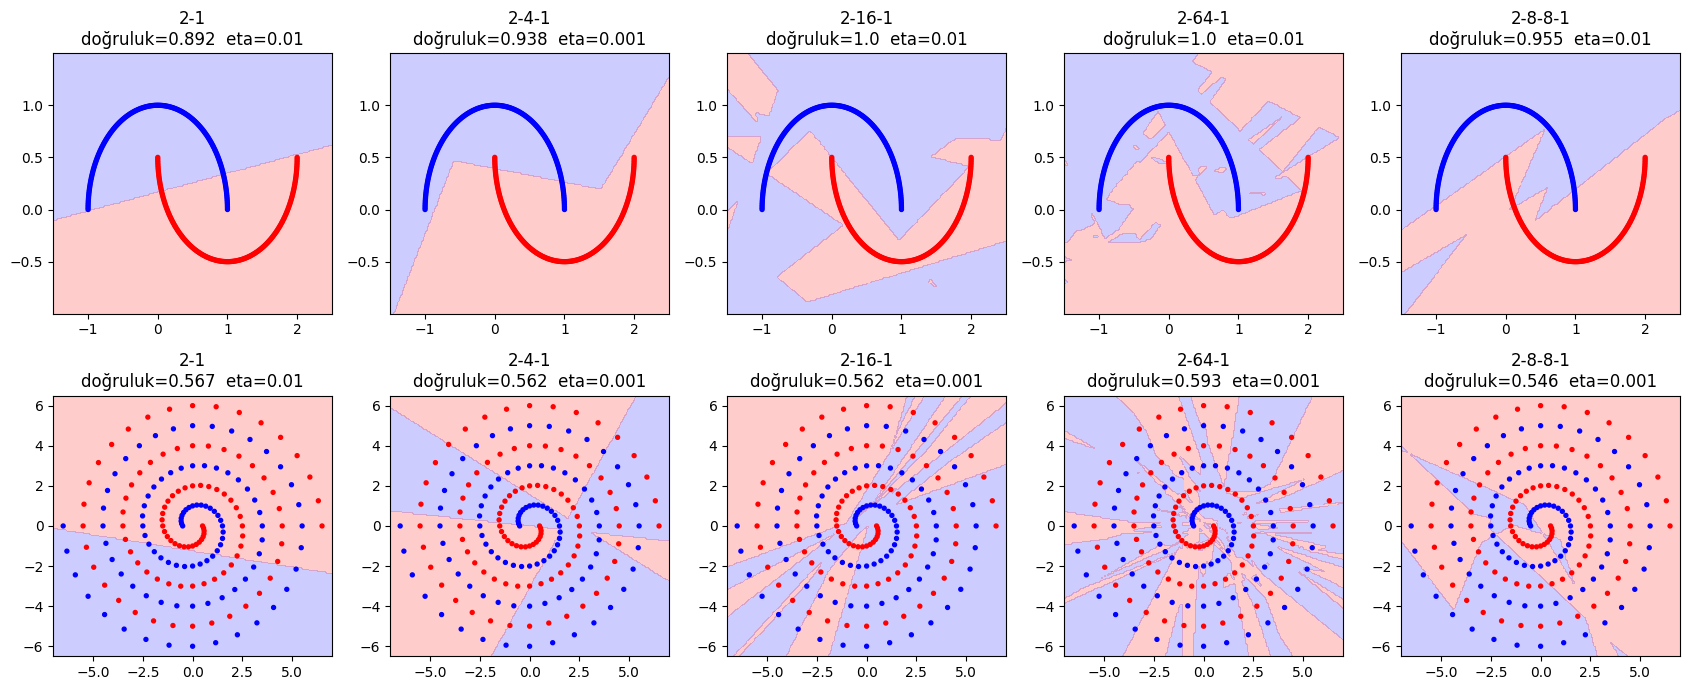

In [10]:
plt.figure(figsize=(17, 7))
k = 1

for data_name in datasets:
    X, y = datasets[data_name]

    for arch_name in ARCHS:
        best_acc, best_weights, eta = best_models[data_name + " " + arch_name]

        plt.subplot(2, 5, k)
        plot_boundary(best_weights, X, y, arch_name + "\ndoğruluk=" + str(round(best_acc, 3)) + "  eta=" + str(eta))

        k = k + 1

plt.tight_layout()
plt.show()

## Madde 6

In [11]:
def mean_cosine(W):
    total = 0
    count = 0
    for i in range(len(W)):
        for j in range(i + 1, len(W)):
            cos = (W[i] @ W[j]) / (np.linalg.norm(W[i]) * np.linalg.norm(W[j]))
            total = total + cos
            count = count + 1
    return total / count


rows = []

for data_name in datasets:
    X, y = datasets[data_name]

    for eta in ETAS:
        W_before = init_weights([2, 16, 1], 0)[0]

        best_acc, best_weights, final_weights, history = train(X, y, [2, 16, 1], eta, seed=0)
        W_after = final_weights[0]

        diff_before = W_before[0] - W_before[1]
        diff_after = W_after[0] - W_after[1]
        diff_same = np.allclose(diff_before, diff_after)

        rows.append([data_name, eta, round(mean_cosine(W_before), 2), round(mean_cosine(W_after), 2), diff_same])

display(pd.DataFrame(rows, columns=["veri", "eta", "benzerlik (önce)", "benzerlik (sonra)", "nöron farkı sabit mi"]))

,veri,eta,benzerlik (önce),benzerlik (sonra),nöron farkı sabit mi
0,first_problem (hilal),0.001,-0.03,0.46,True
1,first_problem (hilal),0.010,-0.03,0.96,True
2,first_problem (hilal),0.100,-0.03,1.00,True
3,first_problem (hilal),1.000,-0.03,1.00,True
4,second_problem (spiral),0.001,-0.03,0.72,True
5,second_problem (spiral),0.010,-0.03,0.99,True
6,second_problem (spiral),0.100,-0.03,1.00,True
7,second_problem (spiral),1.000,-0.03,1.00,True


In [12]:
rows = []

for data_name in datasets:
    X, y = datasets[data_name]

    for arch_name in ["2-16-1", "2-64-1", "2-8-8-1"]:
        layers = ARCHS[arch_name]

        total = 0
        for seed in SEEDS:
            best_acc, best_weights, final_weights, history = train(X, y, layers, 0.01, seed=seed, update_hidden=False)
            total = total + best_acc
        frozen_mean = total / len(SEEDS)

        row = [data_name, arch_name, frozen_mean]

        part = results[(results["veri"] == data_name) & (results["mimari"] == arch_name)]
        means = part.groupby("eta")["doğruluk"].mean()
        for eta in ETAS:
            row.append(means[eta])

        rows.append(row)

table = pd.DataFrame(rows, columns=["veri", "mimari", "gizli katman donuk", "eta=0.001", "eta=0.01", "eta=0.1", "eta=1.0"])
display(table.round(3))

,veri,mimari,gizli katman donuk,eta=0.001,eta=0.01,eta=0.1,eta=1.0
0,first_problem (hilal),2-16-1,0.972,0.962,0.976,0.912,0.863
1,first_problem (hilal),2-64-1,1.000,0.964,0.996,0.912,0.864
2,first_problem (hilal),2-8-8-1,0.772,0.877,0.894,0.859,0.649
3,second_problem (spiral),2-16-1,0.592,0.544,0.544,0.512,0.505
4,second_problem (spiral),2-64-1,0.627,0.562,0.556,0.512,0.505
5,second_problem (spiral),2-8-8-1,0.559,0.526,0.529,0.506,0.515
